# 02 — Exploratory Data Analysis

**Owner:** Shaik Tajuddin · **Phase 1, step 3**

Reads the committed `data/processed/clean.parquet` (2,818,006 × 30) produced by
[`01_cleaning.ipynb`](01_cleaning.ipynb).

This notebook ends with a list of findings that **change modelling decisions** — it is
not a gallery of plots. Each section states what was found and what the team should do
about it. Figures are written to `reports/figures/` for the IEEE report.


In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from src.clean import MEASUREMENTS
from src.config import FIGURES, TARGET_COLUMN as T
from src.evaluate_api import load_data

sns.set_theme(style='whitegrid', context='notebook')
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 42

df = load_data()
print(f'{len(df):,} rows x {df.shape[1]} columns   target: {T}')


2,818,006 rows x 30 columns   target: CCME_Values


## 1. The target is censored at its ceiling

**Finding: 35.92 % of all rows have `CCME_Values` exactly 100.0.**

The index is bounded at 100 and a third of the dataset sits on that boundary. The
75th, 90th and 99th percentiles are all exactly 100 — the distribution has no upper
tail at all, only a spike.

**Why this changes modelling:**

- A model can score well by learning *"predict 100"* for a third of the data. R² and
  RMSE will look flattering without the model understanding any chemistry.
- Residuals above 100 are impossible, so errors are asymmetric by construction and
  residual plots will be one-sided at the ceiling.
- The honest framing is a **censored regression problem**. At minimum the report must
  state it; ideally we also report metrics split by *at ceiling* versus *below ceiling*,
  because they are effectively two different prediction tasks.


In [2]:
n = len(df)
ceiling = (df[T] == 100.0)
print(f'exactly 100.0 : {ceiling.sum():,}  ({100*ceiling.mean():.2f}%)')
print(f'skew          : {df[T].skew():.3f}')
print(df[T].quantile([.01,.1,.25,.5,.75,.9,.99]).round(3).to_string())


exactly 100.0 : 1,012,105  (35.92%)
skew          : -1.187
0.01     40.879
0.10     51.766
0.25     77.048
0.50     90.491
0.75    100.000
0.90    100.000
0.99    100.000


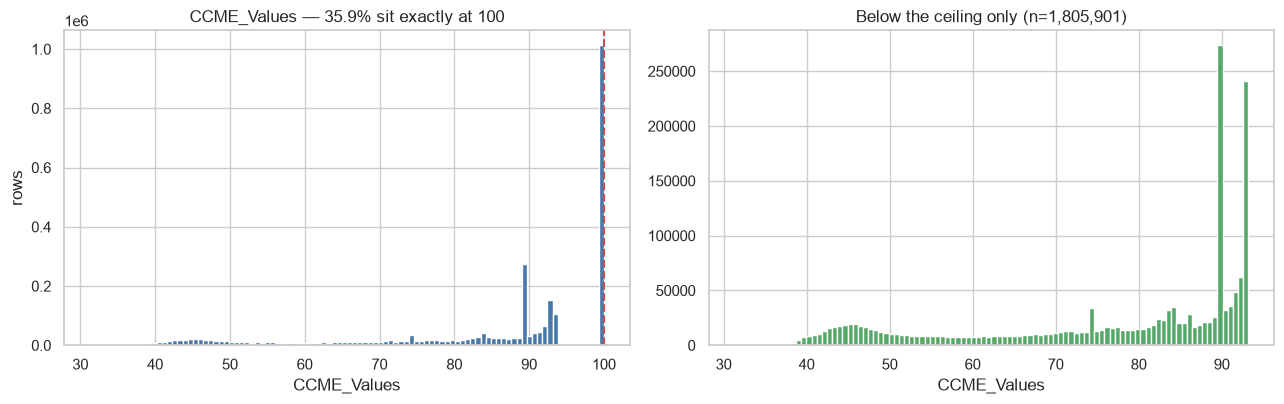

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].hist(df[T], bins=100, color='#4878A8')
ax[0].set(title=f'CCME_Values — {100*ceiling.mean():.1f}% sit exactly at 100',
          xlabel='CCME_Values', ylabel='rows')
ax[0].axvline(100, color='#C44E52', ls='--', lw=1.5)

below = df.loc[~ceiling, T]
ax[1].hist(below, bins=100, color='#55A868')
ax[1].set(title=f'Below the ceiling only (n={len(below):,})', xlabel='CCME_Values')
plt.tight_layout(); plt.savefig(FIGURES/'target_distribution.png', dpi=150); plt.show()


### The ceiling is not spread evenly across countries

**Finding: the share of rows at the ceiling ranges from 20.9 % (England) to 84.5 % (USA).**

Combined with England being 75.3 % of the dataset, this means the target's *shape*
differs by country. A split that mixes countries trains on one distribution and tests
on another; a split that separates them makes the test set a different problem.
Parth needs this before choosing the split key.


,rows,mean_target,pct_at_ceiling
Country,,,
England,2127897,80.73,20.93
USA,405245,98.44,84.47
Ireland,234993,98.11,84.23
China,45977,96.51,54.59
Canada,3894,90.11,34.93


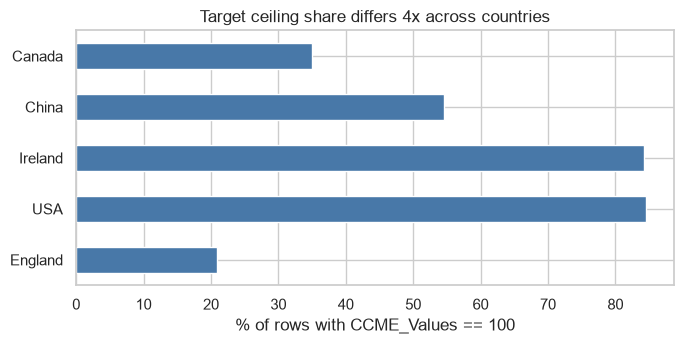

In [4]:
by_country = (df.assign(at_ceiling=ceiling)
                .groupby('Country', observed=True)
                .agg(rows=(T,'size'), mean_target=(T,'mean'), pct_at_ceiling=('at_ceiling','mean')))
by_country['pct_at_ceiling'] = (100*by_country['pct_at_ceiling']).round(2)
by_country = by_country.sort_values('rows', ascending=False).round(2)
display(by_country)

fig, ax = plt.subplots(figsize=(7, 3.6))
by_country['pct_at_ceiling'].plot.barh(ax=ax, color='#4878A8')
ax.set(xlabel='% of rows with CCME_Values == 100', ylabel='',
       title='Target ceiling share differs 4x across countries')
plt.tight_layout(); plt.savefig(FIGURES/'ceiling_by_country.png', dpi=150); plt.show()


## 2. Measurement distributions are extremely skewed

**Finding: skewness reaches 11.98 (ammonia) with kurtosis 222.**

| Column | Skew | Skew after log1p |
| :--- | ---: | ---: |
| Ammonia | 11.98 | 3.35 |
| Biochemical Oxygen Demand | 10.21 | 2.72 |
| Orthophosphate | 8.94 | 2.61 |
| Nitrate | 6.24 | 0.24 |

**Why this changes modelling:** trees are invariant to monotone transforms, so this
barely affects Random Forest or XGBoost — but the Phase 2 MLP is **not** invariant, and
neither is any distance- or gradient-based method. This is direct evidence for
Himanshu's log-transform features, and the ablation should test them on the MLP rather
than assuming they help the trees.


In [5]:
skew_tbl = pd.DataFrame({
    'skew': [df[c].skew() for c in MEASUREMENTS],
    'kurtosis': [df[c].kurtosis() for c in MEASUREMENTS],
    'skew_log1p': [np.log1p(df[c].clip(lower=0)).skew() for c in MEASUREMENTS],
}, index=MEASUREMENTS).round(2).sort_values('skew', ascending=False)
display(skew_tbl)


,skew,kurtosis,skew_log1p
Ammonia (mg/l),11.98,221.66,3.35
Biochemical Oxygen Demand (mg/l),10.21,117.37,2.72
Orthophosphate (mg/l),8.94,205.60,2.61
Nitrate (mg/l),6.24,82.35,0.24
pH (ph units),3.12,162.16,-2.75
Temperature (cel),3.11,30.14,-0.67
Nitrogen (mg/l),2.39,7.21,0.19
Dissolved Oxygen (mg/l),-1.46,4.57,-3.40


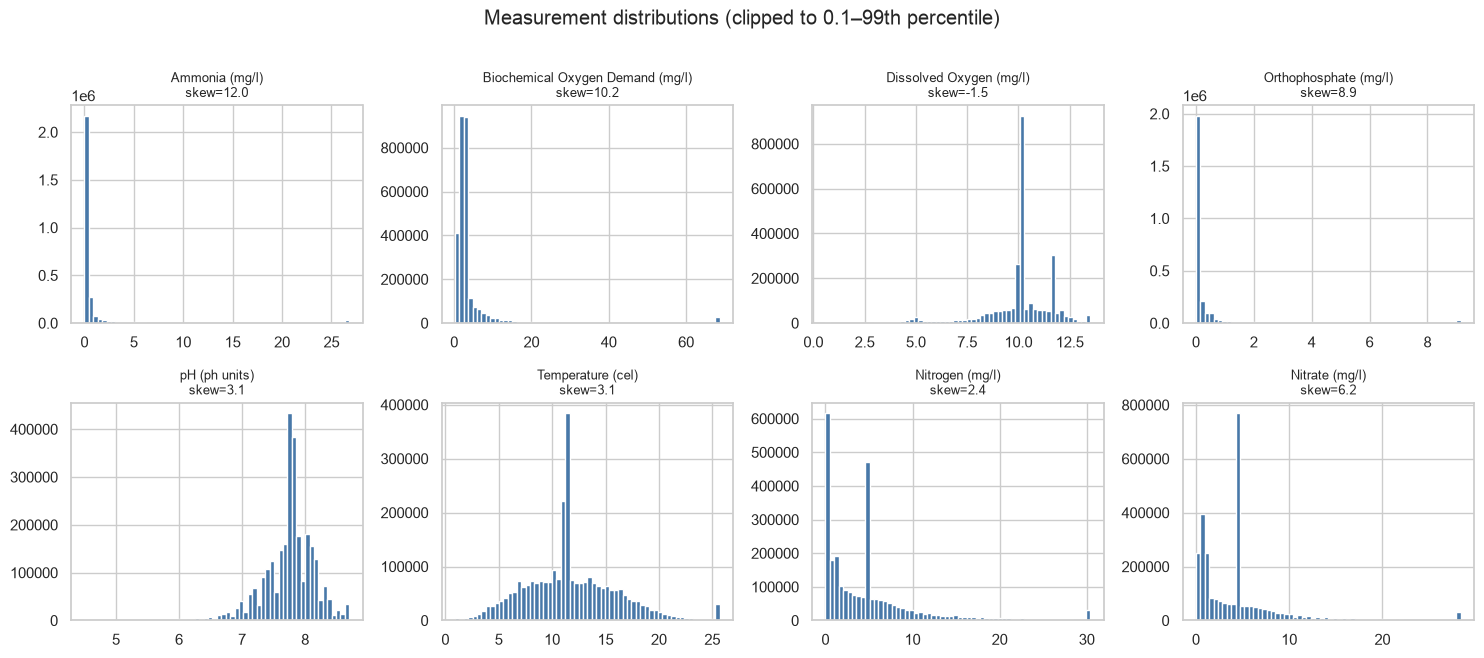

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, c in zip(axes.ravel(), MEASUREMENTS):
    lo, hi = df[c].quantile([0.001, 0.99])
    ax.hist(df[c].clip(lo, hi), bins=60, color='#4878A8')
    ax.set_title(f'{c}\nskew={df[c].skew():.1f}', fontsize=9)
fig.suptitle('Measurement distributions (clipped to 0.1–99th percentile)', y=1.01)
plt.tight_layout(); plt.savefig(FIGURES/'measurement_distributions.png', dpi=150); plt.show()


## 3. Correlation with the target

**Finding: orthophosphate has a Spearman correlation of −0.917 with the target.**

That is close to a monotone function, and it is exactly what Parth's leakage proof
predicts: the CCME index is computed *from* these columns, and orthophosphate carries
the tightest guideline threshold (0.05 mg/l), so it dominates the excursion term.

**Finding: dissolved oxygen correlates ~0 with the target (Pearson −0.031).**

This is the strongest evidence yet that the upstream formula handles DO incorrectly.
DO is a *more-is-better* parameter — low oxygen means poor water — but the harmonization
treats 14.0 mg/l as an upper bound to stay beneath. If DO were being scored correctly it
would be one of the most informative columns in water-quality work; instead it carries
almost no signal. **Flagged for Parth; this belongs in the report's Limitations.**


In [7]:
sub = df[MEASUREMENTS + [T]].sample(400_000, random_state=SEED)
corr = pd.DataFrame({
    'pearson': sub.corr('pearson')[T].drop(T),
    'spearman': sub.corr('spearman')[T].drop(T),
}).round(3).sort_values('spearman')
display(corr)


,pearson,spearman
Orthophosphate (mg/l),-0.657,-0.917
Ammonia (mg/l),-0.393,-0.721
Nitrogen (mg/l),-0.611,-0.601
Biochemical Oxygen Demand (mg/l),-0.322,-0.535
Nitrate (mg/l),-0.307,-0.500
Temperature (cel),-0.108,-0.149
Dissolved Oxygen (mg/l),-0.031,-0.021
pH (ph units),0.082,0.110


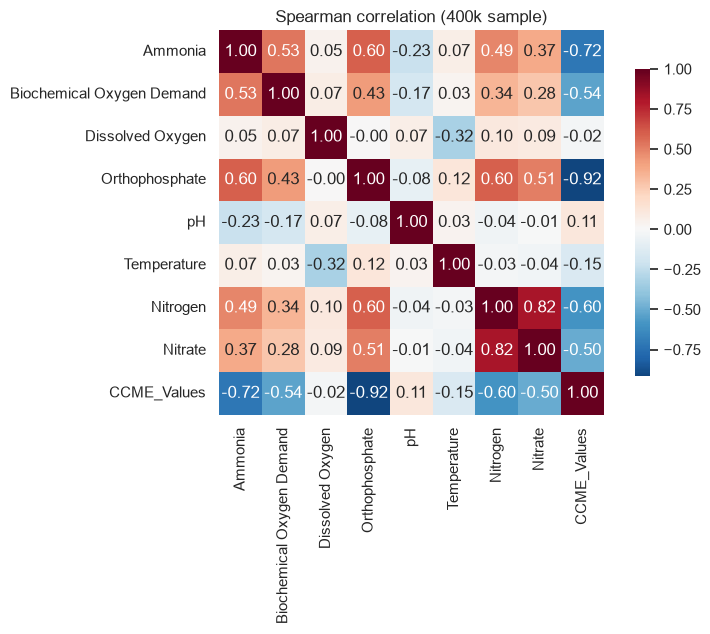

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(sub.corr('spearman'), annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, cbar_kws={'shrink': .8}, ax=ax,
            xticklabels=[c.split(' (')[0] for c in sub.columns],
            yticklabels=[c.split(' (')[0] for c in sub.columns])
ax.set_title('Spearman correlation (400k sample)')
plt.tight_layout(); plt.savefig(FIGURES/'correlation_heatmap.png', dpi=150); plt.show()


## 4. Upstream imputation, quantified

Carried over from cleaning: the file reports zero missing values, but five of eight
measurement columns carry their exact median at 11–32 % of rows. Here is how it is
distributed, and why it is a modelling problem rather than a data-quality one.

**Finding: the fill is almost entirely England — 2.04 suspect measurements per row
against ≤0.04 everywhere else.**

England is 75.3 % of the dataset, so `n_imputed_upstream` is effectively a proxy for
`Country == England`. And the target moves with it. A model can therefore score well by
detecting *which country filled its gaps* rather than by learning chemistry. A
site-separated split cannot break the confound, because it follows the sites.

One caveat on the right-hand panel below: the relationship is clear over 0–3
suspect measurements, which covers 81.7 % of rows. The apparent recovery at 6–8 sits
on 32,535, 657 and 6 rows respectively — that tail is noise, not a reversal, and
should not be read as "more imputation improves water quality".


In [9]:
imp_country = (df.groupby('Country', observed=True)['n_imputed_upstream']
                 .agg(['mean','count']).sort_values('mean', ascending=False).round(3))
display(imp_country)

by_flag = df.groupby('n_imputed_upstream', observed=True)[T].agg(['mean','count']).round(2)
display(by_flag)


,mean,count
Country,,
England,2.037,2127897
Ireland,0.040,234993
China,0.016,45977
USA,0.014,405245
Canada,0.008,3894


,mean,count
n_imputed_upstream,,
0,91.31,1102041
1,83.36,602467
2,78.49,408139
3,75.89,190526
4,81.80,248460
5,81.71,233175
6,84.57,32535
7,89.21,657
8,89.63,6


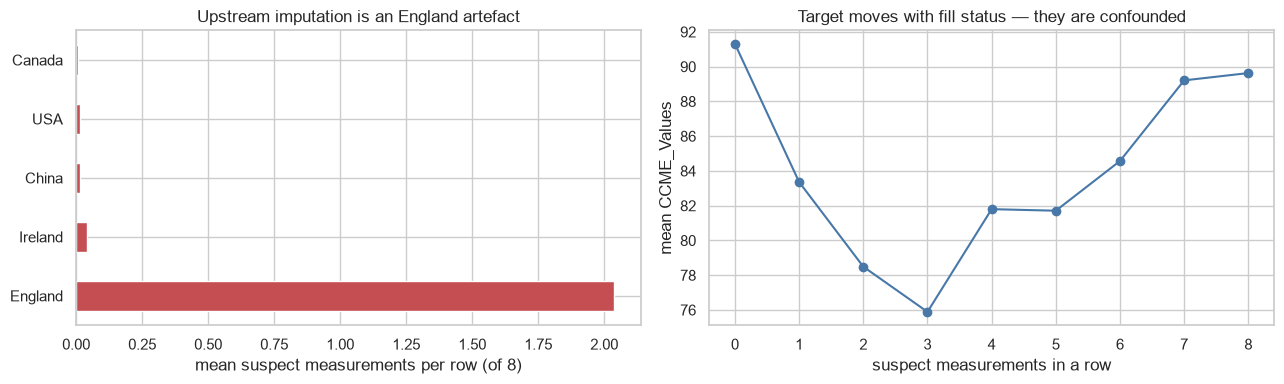

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
imp_country['mean'].plot.barh(ax=ax[0], color='#C44E52')
ax[0].set(xlabel='mean suspect measurements per row (of 8)', ylabel='',
          title='Upstream imputation is an England artefact')

ax[1].plot(by_flag.index, by_flag['mean'], marker='o', color='#4878A8')
ax[1].set(xlabel='suspect measurements in a row', ylabel=f'mean {T}',
          title='Target moves with fill status — they are confounded')
plt.tight_layout(); plt.savefig(FIGURES/'imputation_confound.png', dpi=150); plt.show()


## 5. Composition: what is actually in this dataset

**Finding: 21.3 % of rows are `Effluent` and a further 0.8 % `Sewage` — treatment-works
outflow, not natural surface water. Their mean target is 66.6 against 90.0 for rivers.**

Waterbody type is therefore one of the strongest available predictors, and it is
metadata rather than chemistry. That matters because it is one of the few features
*not* implicated in the formula leakage — so it is genuinely useful — but it also means
a model can separate effluent from river and get most of the way without chemistry.

**Decision the team owes the report:** do we model effluent and surface water together?
Keeping them is defensible, but it must be stated, because "water quality prediction"
implies natural waters to most readers.


In [11]:
wb = (df.assign(at_ceiling=ceiling).groupby('Waterbody Type', observed=True)
        .agg(rows=(T,'size'), mean_target=(T,'mean'), pct_at_ceiling=('at_ceiling','mean')))
wb['pct_at_ceiling'] = (100*wb['pct_at_ceiling']).round(2)
display(wb.sort_values('rows', ascending=False).round(2))


,rows,mean_target,pct_at_ceiling
Waterbody Type,,,
River,1848994,90.02,43.57
Effluent,601491,66.56,3.57
Lake,147694,97.00,79.62
Estuarine,49239,85.10,14.73
Bay,45977,96.51,54.59
Sea Water,31928,84.34,20.20
Canal,28569,86.53,26.33
Sewage,23774,53.66,1.58
Marine,23056,97.07,60.73


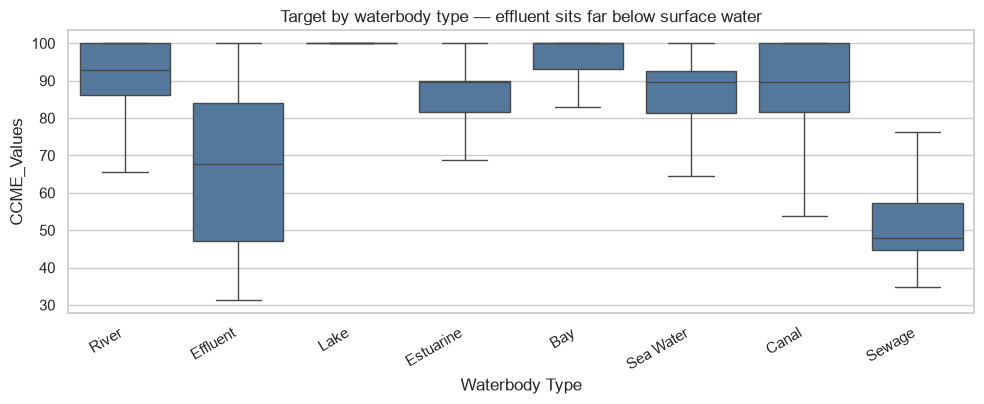

In [12]:
order = wb.sort_values('rows', ascending=False).head(8).index
fig, ax = plt.subplots(figsize=(10, 4.2))
sns.boxplot(data=df[df['Waterbody Type'].isin(order)], x='Waterbody Type', y=T,
            order=order, showfliers=False, ax=ax, color='#4878A8')
ax.set(title='Target by waterbody type — effluent sits far below surface water')
plt.xticks(rotation=30, ha='right')
plt.tight_layout(); plt.savefig(FIGURES/'target_by_waterbody.png', dpi=150); plt.show()


## 6. Coverage in space and time

**Finding: 82 % of rows fall in 2000–2019, England's records begin only in 2000, and
Canada contributes 3,894 rows (0.14 %).**

**Why this changes modelling:** a time-separated split would cut almost entirely on
England, making the test set a different country mix from the training set. Site
separation on `Area` (61,689 sites) is the safer key — but note the confound in §4
follows the sites too.


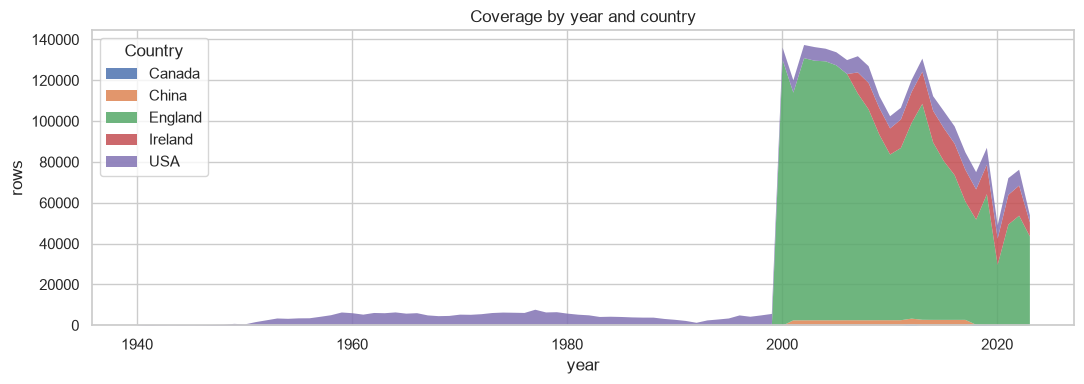

unique sites (Area): 61,689
rows 2000-2019     : 82.5%


In [13]:
df['year'] = df['Date_parsed'].dt.year
per_year = df.groupby(['year','Country'], observed=True).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(11, 4))
per_year.plot.area(ax=ax, linewidth=0, alpha=.85)
ax.set(xlabel='year', ylabel='rows', title='Coverage by year and country')
plt.tight_layout(); plt.savefig(FIGURES/'coverage_by_year.png', dpi=150); plt.show()

print(f"unique sites (Area): {df['Area'].nunique():,}")
print(f"rows 2000-2019     : {df['year'].between(2000,2019).mean()*100:.1f}%")


## 7. Outliers

**Finding: the IQR rule marks 2.0–16.6 % of rows per column as outliers.**

**Decision: do not remove them.** At this scale and skew the IQR rule is measuring
skewness, not error — on a distribution with kurtosis 222 it flags the legitimate tail.
Genuinely impossible readings are already flagged in cleaning (`flag_any_impossible`,
7,676 rows). Trees handle the rest natively; the MLP needs the log transforms from §2.


In [14]:
iqr_tbl = {}
for c in MEASUREMENTS:
    q1, q3 = df[c].quantile([.25,.75]); iqr = q3-q1
    k = ((df[c] < q1-1.5*iqr) | (df[c] > q3+1.5*iqr)).sum()
    iqr_tbl[c] = {'outliers': int(k), 'pct': round(100*k/n, 2)}
display(pd.DataFrame(iqr_tbl).T.sort_values('pct', ascending=False))
print(f"already flagged impossible in cleaning: {int(df['flag_any_impossible'].sum()):,}")


,outliers,pct
Orthophosphate (mg/l),467990.0,16.61
Biochemical Oxygen Demand (mg/l),407927.0,14.48
Ammonia (mg/l),402802.0,14.29
Dissolved Oxygen (mg/l),352440.0,12.51
Nitrate (mg/l),247545.0,8.78
Nitrogen (mg/l),216422.0,7.68
pH (ph units),131323.0,4.66
Temperature (cel),57560.0,2.04


already flagged impossible in cleaning: 7,676


## Findings that change modelling decisions

| # | Finding | Consequence | Owner |
| :-- | :--- | :--- | :--- |
| 1 | **35.92 % of the target is exactly 100.0** | Censored regression. Report metrics split by at-ceiling vs below-ceiling, or a model will look good by predicting the ceiling | Satya (metrics), Parth (evaluation) |
| 2 | Ceiling share varies 20.9 %–84.5 % by country | The target's *shape* differs by country; the split key changes what is being tested | Parth |
| 3 | Skew up to 11.98, kurtosis 222 | Log transforms for the Phase 2 MLP; trees are unaffected, so ablate on the MLP | Himanshu, Jivit |
| 4 | Orthophosphate Spearman **−0.917** | Confirms the formula leakage empirically — one feature nearly determines the index | Parth, Jivit |
| 5 | Dissolved oxygen correlates **≈0** | The upstream formula likely treats DO backwards. Limitations section | Parth |
| 6 | Imputation is an England artefact, confounded with the target | Ablate with and without the `__imputed_upstream` flags; no split fixes it | Jivit, Parth |
| 7 | 22 % effluent/sewage, mean target 66.6 vs 90.0 | Decide explicitly whether to model them together; state it either way | team |
| 8 | 82 % of rows in 2000–2019, England starts 2000 | Prefer a site-separated split over a time-separated one | Parth |
| 9 | IQR flags up to 16.6 % as outliers | Do not remove — it is measuring skew. Keep the cleaning flags only | Taj (done) |

### What I would tell the team in one line

The two numbers that should shape Phase 1 are **35.92 %** (the target is censored, so
trust metrics less than they look) and **−0.917** (one input nearly determines the
target, so a high R² proves formula recovery, not water-quality understanding).


In [15]:
print('figures written to reports/figures/:')
for f in sorted(FIGURES.glob('*.png')): print(f'  {f.name:34s} {f.stat().st_size/1024:6.0f} KB')


figures written to reports/figures/:
  ceiling_by_country.png                 30 KB
  correlation_heatmap.png               162 KB
  coverage_by_year.png                   64 KB
  imputation_confound.png                77 KB
  measurement_distributions.png         108 KB
  target_by_waterbody.png                48 KB
  target_distribution.png                52 KB
